In [74]:
tomo_path = "/goliath/processing/Gouaux/CJS/BestTomo/ProcessingCJS/tomograms/15F1/TOP_TOMOS/20241030_AMmilled12-1_15"


In [75]:
from synaptic_tomo_tools.activezone import import_membrane_segmentations_from_glb, find_active_zones_from_glb, define_active_zonogram, extract_active_zonogram, transform_coordinates_to_active_zonogram
from matplotlib import pyplot as plt
import numpy as np
from pathlib import Path
import starfile
import torch
from torch_affine_utils.transforms_3d import T
from torch_affine_utils.utils import homogenise_coordinates
import einops
import trimesh

In [88]:
membranes_glb = import_membrane_segmentations_from_glb(tomo_path)
active_zones_glb = find_active_zones_from_glb(membranes_glb)
active_zonograms = define_active_zonogram(active_zones_glb)
transformed_tomo = extract_active_zonogram(active_zonograms=active_zonograms, active_zones=active_zones_glb, tomo_path=tomo_path,tomo_type='ddw')

Presynaptic membrane 1 volume: 0.000915 µm³ (576291 vertices, 1152320 faces)
Presynaptic membrane 2 volume: 0.001111 µm³ (652482 vertices, 1304964 faces)
Postsynaptic membrane 1 volume: 0.001185 µm³ (721748 vertices, 1443496 faces)
Found active zone: active_zone_pre1_post1 with 111280 presynaptic and 101361 postsynaptic points
Found active zone: active_zone_pre2_post1 with 94263 presynaptic and 181591 postsynaptic points
Defining active zonogram
Rendering active zonogram


In [77]:
aunps_dir = Path(tomo_path) / "best_alignment" / "aunps"
star_file = aunps_dir / f"aunp_tm_BP_active_zone_0.star"
star_data = starfile.read(star_file)


coordinates = star_data[['faCoordinateX', 'faCoordinateY', 'faCoordinateZ']].values
transformed_coordinates = transform_coordinates_to_active_zonogram(coordinates, active_zonograms['zonogram_data']['active_zone_pre1_post1'])


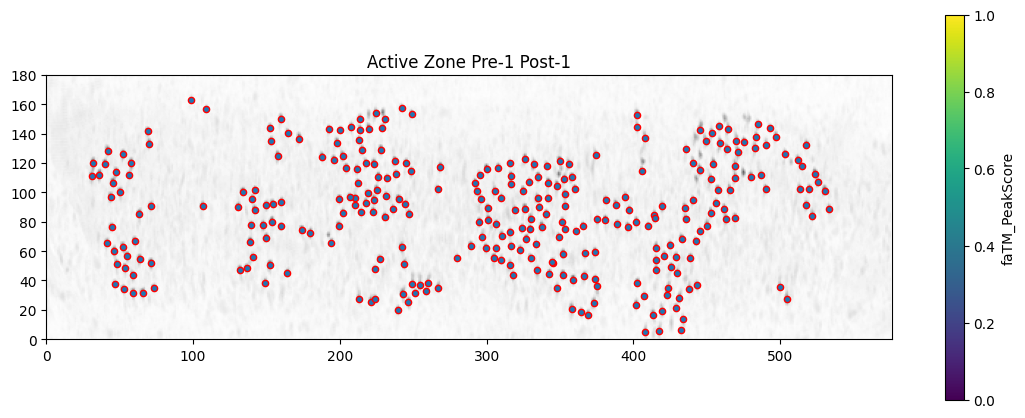

In [78]:
plt.figure(figsize=(30, 5))
plt.subplot(1, 2, 1)
plt.title('Active Zone Pre-1 Post-1')
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')
plt.scatter(
    transformed_coordinates[:, 0],
    transformed_coordinates[:, 1],
    s=20,                # circle size
    edgecolors='red',       # red edge
    alpha=1,             # transparency
)
plt.xlim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[2])
plt.ylim(0, transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'].shape[1])
plt.colorbar(label='faTM_PeakScore')

In [91]:
ps_mesh = active_zones_glb['active_zones']['active_zone_pre1_post1']['active_postsynaptic_mesh']
print(len(ps_mesh.vertices))
#Simplify mesh
ps_mesh_simplified = ps_mesh.simplify_quadric_decimation(0.99)
print(len(ps_mesh_simplified.vertices))


101344
1085


In [80]:
# Generate cKDTree of vertices
from scipy.spatial import cKDTree
tree = cKDTree(ps_mesh.vertices)
#Generate a cKDTree of aunps
tree_aunps = cKDTree(coordinates)
print(len(coordinates))
# Iterate of vertices in ps_mesh_simplified and find all vertices in ps_mesh within 25 and average their normals
v=ps_mesh_simplified.vertices[394]
idxs = tree.query_ball_point(v, 25)
normals = ps_mesh.vertex_normals[idxs]
avg_normal = np.mean(normals, axis=0)
avg_normal /= np.linalg.norm(avg_normal)
# Find all aunps with 25 of line through v in direction of avg_normal
line_points = np.array([v + t * avg_normal for t in np.linspace(0, 25, 100)])
idxs_aunps = tree_aunps.query_ball_point(line_points, 25)
# Generate list of unique inds in idxs_aunps
unique_idxs_aunps = set()
for idx_list in idxs_aunps:
    unique_idxs_aunps.update(idx_list)
# Cylinder staring at v in direction of avg_normal with radius 25
cylinder = trimesh.creation.cylinder(radius=25, height=50, sections=32)
# Move cylinder to v and rotate to avg_normal
cylinder.apply_translation([0, 0, 25])
z_axis = np.array([0, 0, 1])
matrix = trimesh.geometry.align_vectors(z_axis, avg_normal)
cylinder.apply_transform(matrix=matrix)
cylinder.apply_translation(v)
# Make point cloud of aunps

aunps = trimesh.points.PointCloud(coordinates)
scene = trimesh.Scene([ps_mesh, cylinder, aunps])
scene.show()

304


In [81]:
# Generate cKDTree of vertices
from scipy.spatial import cKDTree
tree = cKDTree(ps_mesh.vertices)
#Generate a cKDTree of aunps
tree_aunps = cKDTree(coordinates)
print(len(coordinates))
# Iterate of vertices in ps_mesh_simplified and find all vertices in ps_mesh within 25 and average their normals
num_aunps_at_vertex = []
for v in ps_mesh_simplified.vertices:
    idxs = tree.query_ball_point(v, 25)
    normals = ps_mesh.vertex_normals[idxs]
    avg_normal = np.mean(normals, axis=0)
    avg_normal /= np.linalg.norm(avg_normal)
    # Find all aunps with 25 of line through v in direction of avg_normal
    line_points = np.array([v + t * avg_normal for t in np.linspace(0, 25, 100)])
    idxs_aunps = tree_aunps.query_ball_point(line_points, 25)
    # Generate list of unique inds in idxs_aunps
    unique_idxs_aunps = set()
    for idx_list in idxs_aunps:
        unique_idxs_aunps.update(idx_list)
    num_aunps_at_vertex.append(len(unique_idxs_aunps))


304


In [82]:
v_array = np.array(ps_mesh_simplified.vertices)
v_array.shape

(20677, 3)

In [83]:
coordinates.shape

(304, 3)

In [84]:
t_v = transform_coordinates_to_active_zonogram(v_array, active_zonograms['zonogram_data']['active_zone_pre1_post1'])

In [85]:
area_of_circle = np.pi * (25 ** 2)  # Area = πr²
packing_coefficient = ((np.array(num_aunps_at_vertex)/2) / area_of_circle)   # Each AMPA receptor occupies ~84 nm²


(180, 576)
(20677, 2)
(180, 576)


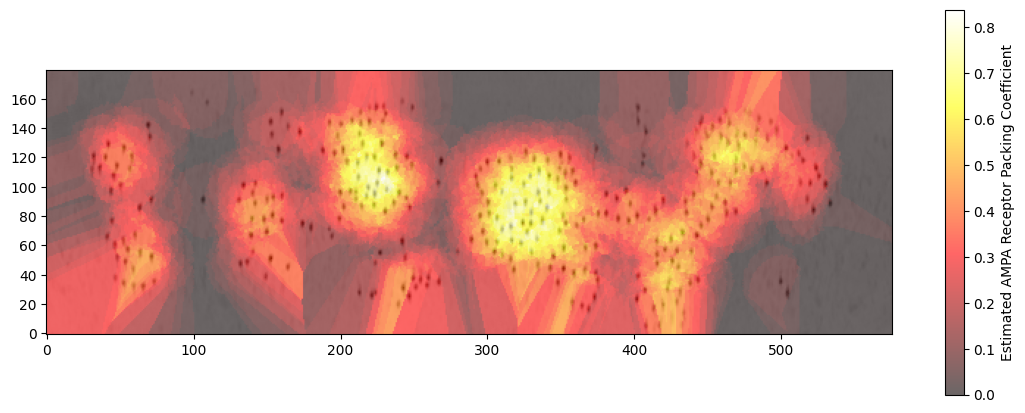

In [ ]:
plt.figure(figsize=(30, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')
density_map = np.zeros_like(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0))
print(density_map.shape)
# Interpolate every pixel on density_map between centers and assign packing_coefficient values
from scipy.interpolate import griddata
grid_x, grid_y = np.mgrid[0:density_map.shape[0], 0:density_map.shape[1]]
print(t_v[:,:2].shape)
density_map = griddata(t_v[:,:2], packing_coefficient*122, (grid_y, grid_x), method='nearest', fill_value=0)
print(density_map.shape)
plt.imshow(density_map, cmap='hot', alpha=0.6, origin='lower')
# Draw circle with radius 25 arount first center
#circle = plt.Circle(centers[25], 25, color='blue', fill=False)
#plt.gca().add_artist(circle)
plt.colorbar(label='Estimated AMPA Receptor Packing Coefficient')

In [58]:
for i, a in enumerate(num_aunps_at_vertex):
    if a > 24:
        print(i, a)

88 25
394 25


# 2D Version

In [16]:
aunp_points_2d = transformed_coordinates[:, :2]

In [17]:
def count_points_in_sliding_circle(points, radius, step_size=10):
    """
    Count points within a sliding circle across the 2D space
    """
    # Get bounds of the point cloud
    min_x, min_y = np.min(points, axis=0)
    max_x, max_y = np.max(points, axis=0)
    
    # Create grid of circle centers
    x_centers = np.arange(min_x, max_x + step_size, step_size)
    y_centers = np.arange(min_y, max_y + step_size, step_size)
    
    counts = []
    centers = []
    
    for x_center in x_centers:
        for y_center in y_centers:
            # Calculate distances from center to all points
            distances = np.sqrt((points[:, 0] - x_center)**2 + (points[:, 1] - y_center)**2)
            
            # Count points within radius
            count = np.sum(distances <= radius)
            
            counts.append(count)
            centers.append([x_center, y_center])
    
    return np.array(counts), np.array(centers)

# Calculate counts with sliding circle of radius 50
counts, centers = count_points_in_sliding_circle(aunp_points_2d, radius=25)

print(f"Maximum points in circle: {np.max(counts)}")
print(f"Average points in circle: {np.mean(counts):.2f}")
print(f"Total circle positions tested: {len(counts)}")

Maximum points in circle: 26
Average points in circle: 6.84
Total circle positions tested: 884


In [52]:
area_of_circle = np.pi * (25 ** 2)  # Area = πr²
density_per_micron2 = counts / area_of_circle
packing_coefficient = ((counts/2) / area_of_circle)   # Each AMPA receptor occupies ~84 nm²
print(f"Maximum density (points/µm²): {np.max(density_per_micron2)*61:.4f}")
print(f"Average density (points/µm²): {np.mean(density_per_micron2)*61:.4f}")

Maximum density (points/µm²): 0.8077
Average density (points/µm²): 0.2125


(184, 576)
(184, 576)


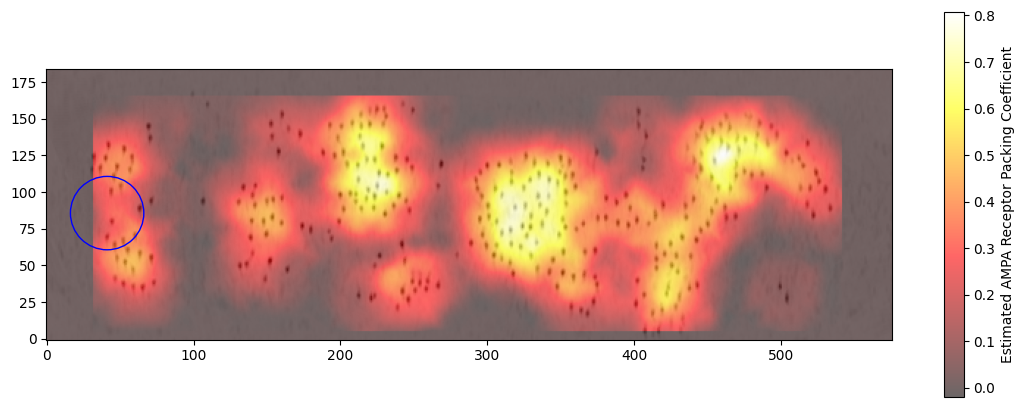

In [56]:
plt.figure(figsize=(30, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')

density_map = np.zeros_like(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0))
print(density_map.shape)
# Interpolate every pixel on density_map between centers and assign packing_coefficient values
from scipy.interpolate import griddata
grid_x, grid_y = np.mgrid[0:density_map.shape[0], 0:density_map.shape[1]]
density_map = griddata(centers, packing_coefficient*122, (grid_y, grid_x), method='cubic', fill_value=0)
print(density_map.shape)
plt.imshow(density_map, cmap='hot', alpha=0.6, origin='lower')
# Draw circle with radius 25 arount first center
circle = plt.Circle(centers[25], 25, color='blue', fill=False)
plt.gca().add_artist(circle)
plt.colorbar(label='Estimated AMPA Receptor Packing Coefficient')

(184, 576)
(184, 576)


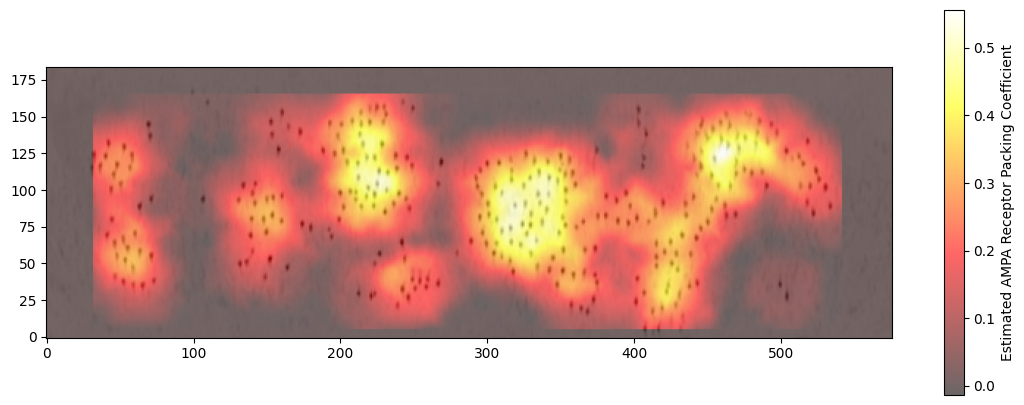

In [54]:
plt.figure(figsize=(30, 5))
plt.subplot(1, 2, 1)
plt.imshow(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0), cmap='gray',origin='lower')

density_map = np.zeros_like(np.min(transformed_tomo['rendered_zonograms']['active_zone_pre1_post1']['transformed_tomogram'], axis=0))
print(density_map.shape)
# Interpolate every pixel on density_map between centers and assign packing_coefficient values
from scipy.interpolate import griddata
grid_x, grid_y = np.mgrid[0:density_map.shape[0], 0:density_map.shape[1]]
density_map = griddata(centers, packing_coefficient*84, (grid_y, grid_x), method='cubic', fill_value=0)
print(density_map.shape)
plt.imshow(density_map, cmap='hot', alpha=0.6, origin='lower')
plt.colorbar(label='Estimated AMPA Receptor Packing Coefficient')